# Imports and predictions

In [7]:
import pandas as pd
import numpy as np

from demand.config import PROCESSED
from demand.simulation import add_costs, period_table, summarize, sensitivity, best_factor, scale_orders

predictions = pd.read_parquet(PROCESSED / "predictions.parquet")
table = period_table(predictions)
table.groupby("fold").size().to_dict()

{1: 600, 2: 600, 3: 600, 4: 600, 5: 600, 6: 600, 7: 600, 8: 600, 9: 600}

# Cost on walk-forward folds

In [8]:
cv = add_costs(table[table.fold <= 8])
summarize(cv).round(3)

,actual,short,excess,cost,fill_rate,cost_per_unit,cost_vs_reference
model,,,,,,,
lgbm_scaled,27118468.0,1166596.792,614627.783,4114418.161,0.957,0.152,0.250
xgb_scaled,27118468.0,1206028.023,587706.204,4205790.274,0.956,0.155,0.233
rnn,27118468.0,1652132.775,445418.781,5401817.107,0.939,0.199,0.015
ridge,27118468.0,1363392.210,1319095.786,5409272.416,0.950,0.199,0.013
lstm,27118468.0,1640441.106,529745.752,5451069.069,0.940,0.201,0.006
seasonal_median_4w,27118468.0,1443387.359,1152602.142,5482764.219,0.947,0.202,0.000


# Sensitivity to the cost ratio

In [9]:
sensitivity(table[table.fold <= 8])

,1:1,2:1,3:1,4:1,5:1
model,,,,,
lgbm_scaled,0.314,0.270,0.250,0.238,0.230
lstm,0.164,0.057,0.006,-0.024,-0.043
ridge,-0.033,-0.002,0.013,0.022,0.028
rnn,0.192,0.072,0.015,-0.018,-0.040
seasonal_median_4w,0.000,0.000,0.000,0.000,0.000
xgb_scaled,0.309,0.257,0.233,0.219,0.209


# Safety factor

In [10]:
factors = np.round(np.arange(0.9, 1.31, 0.025), 3)
best, curve = best_factor(table[table.fold <= 8], factors)
best

model
lgbm_scaled           1.075
lstm                  1.100
ridge                 1.075
rnn                   1.100
seasonal_median_4w    1.075
xgb_scaled            1.075
dtype: float64

# Safety factor on hold-out

In [11]:
hold = table[table.fold == 9]
tuned = pd.concat([scale_orders(hold[hold.model == model], factor) for model, factor in best.items()])

plain = summarize(add_costs(hold))
with_factor = summarize(add_costs(tuned))

pd.DataFrame({
    "cost, factor 1": plain.cost,
    "cost, tuned factor": with_factor.cost,
    "fill rate, factor 1": plain.fill_rate,
    "fill rate, tuned": with_factor.fill_rate,
    "vs baseline, factor 1": plain.cost_vs_reference,
    "vs baseline, tuned": with_factor.cost_vs_reference,
}).round(3)

,"cost, factor 1","cost, tuned factor","fill rate, factor 1","fill rate, tuned","vs baseline, factor 1","vs baseline, tuned"
model,,,,,,
xgb_scaled,278023.883,364791.419,0.984,0.996,0.132,0.177
lgbm_scaled,286746.466,372475.916,0.984,0.997,0.105,0.160
lstm,298029.208,417997.134,0.984,1.000,0.070,0.057
seasonal_median_4w,320359.347,443497.212,0.985,0.995,0.000,0.000
rnn,330633.726,450756.348,0.982,0.999,-0.032,-0.016
ridge,481118.317,542876.932,0.973,0.987,-0.502,-0.224


# Figure: cost reduction by cost ratio

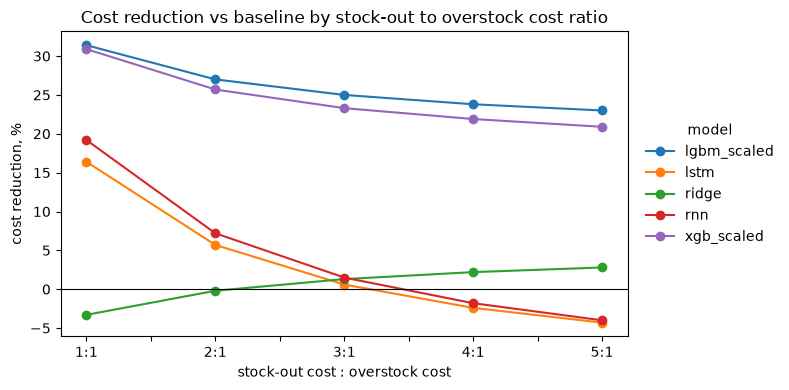

In [12]:
import matplotlib.pyplot as plt

from demand.config import FIGURES

FIGURES.mkdir(parents=True, exist_ok=True)

saving = sensitivity(table[table.fold <= 8]).drop(index="seasonal_median_4w") * 100
ax = saving.T.plot(marker="o", figsize=(8, 4), title="Cost reduction vs baseline by stock-out to overstock cost ratio")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("stock-out cost : overstock cost")
ax.set_ylabel("cost reduction, %")
ax.legend(title="model", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout()
plt.savefig(FIGURES / "cost_sensitivity.png", dpi=150)
plt.show()

# Conclusions

- Setup: the forecast of each model is turned into weekly orders per store and family. Stock-out costs 3 units per missing unit and overstock costs 1 per extra unit (assumed, there are no prices in the data). Models are compared on the 8 walk-forward folds and on the hold-out.
- Walk-forward: XGBoost with the scaled target lowers the cost by 23% against the seasonal median baseline and LightGBM by 25% (the difference between them is small and was not tested). The share of covered demand rises from 94.7% to 95.6-95.7%. RNN, LSTM and Ridge are within 1.5% of the baseline.
- Sensitivity: for cost ratios from 1:1 to 5:1 the boosters are 21-31% cheaper than the baseline, so the result does not depend on the assumed ratio of 3. The networks are better than the baseline only when stock-outs are cheap (1:1 and 2:1) and worse from 4:1, because they under-order. Ridge shows the opposite pattern because it over-orders.
- All models order too little for a 3:1 cost ratio (stock-out units are about twice the overstock units), so ordering above the forecast looks attractive. A factor of 1.075 (1.10 for the networks) minimized the cost on walk-forward.
- Hold-out: the same factor raised the cost for every model (XGBoost 278k to 365k units of cost), because the hold-out month is calm and demand coverage was already 98.4% without a buffer. A fixed safety factor does not transfer between periods and is not recommended.
- Hold-out without the factor: XGBoost is 13% cheaper than the baseline (LightGBM 11%, LSTM 7%, RNN 3% worse, Ridge 50% worse). The gain is smaller than on walk-forward because this month is easier for the baseline.
- Limits: assumed costs in units, weekly netting assumes stock carries over inside the week, no lead times, shelf life or capacity, only two years of data, one hold-out window.
- Next step for a real use: quantile forecasts (for example the 75th percentile) instead of a fixed factor.